In [111]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

In [112]:
#################################
# IMAGE PATHS
#################################
chess_path="images/chess.jpg"
natural_path = "images/natural.jpg"

## Task 1. Harris corners from scratch

In [114]:
checkerboard = cv2.imread(chess_path)
natural = cv2.imread(natural_path)

if checkerboard is None:
    raise FileNotFoundError("Could not load checkerboard.jpg")

if natural is None:
    raise FileNotFoundError("Could not load natural.jpg")
#plt.imshow(checkerboard)

In [80]:
def resize_for_detection(image, max_width=800):
    """
    Resize an image while preserving its aspect ratio.
    """

    height, width = image.shape[:2]

    if width <= max_width:
        return image

    scale = max_width / width

    new_width = int(width * scale)
    new_height = int(height * scale)

    return cv2.resize(
        image,
        (new_width, new_height)
    )

In [81]:
checkerboard = resize_for_detection(
    checkerboard,
    max_width=800
)

natural = resize_for_detection(
    natural,
    max_width=800
)

In [82]:
######################################################
# CONVERT IMAGE TO GRAYSCALE
#####################################################
def to_grayscale(image):
    """
    Convert a BGR image to grayscale.

    If the image is already grayscale, return it unchanged.
    """
    
    if len(image.shape) == 2:
        return image.astype(np.float32)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    return gray.astype(np.float32)

In [83]:
######################################################
# IMPLEMENT CONVOLUTION
#####################################################
def convolution(image, kernel):
    """
    Apply a 2D convolution using OpenCV's optimized
    filtering implementation.
    """

    return cv2.filter2D(
        image,
        cv2.CV_32F,
        kernel
    )

In [84]:
######################################################
# SOBEL GRANDIENT
#####################################################
def sobel_gradients(gray):
    """
    Calculate horizontal and vertical image gradients
    using manually defined Sobel operators.
    """

    # Horizontal Sobel operator
    Sx = np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ], dtype=np.float32)

    # Vertical Sobel operator
    Sy = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32)

    # Convolve image with Sobel operators
    Ix = convolution(gray, Sx)
    Iy = convolution(gray, Sy)

    return Ix, Iy

In [85]:
######################################################
# GAUSSIAN KERNEL
#####################################################
def gaussian_kernel(size=5, sigma=1.0):
    """
    Generate a normalized 2D Gaussian kernel.
    """

    radius = size // 2

    x = np.arange(-radius, radius + 1)
    y = np.arange(-radius, radius + 1)

    X, Y = np.meshgrid(x, y)

    kernel = np.exp(
        -(X**2 + Y**2) / (2 * sigma**2)
    )

    kernel = kernel / np.sum(kernel)

    return kernel.astype(np.float32)

In [86]:
######################################################
# GAUSSIAN SMOOTHING FUNCTION
#####################################################
def gaussian_blur(image, size=5, sigma=1.0):
    """
    Smooth an image using a Gaussian kernel.
    """

    kernel = gaussian_kernel(size, sigma)

    return convolution(image, kernel)

In [87]:
######################################################
# HARRIS CORNER RESPONSE
#####################################################
def harris_response(
    gray,
    gaussian_size=5,
    sigma=1.0,
    k=0.04
):
    """
    Calculate the Harris corner response image.
    """

   
    # Step 1: Image gradients
  
    Ix, Iy = sobel_gradients(gray)

  
    # Step 2: Gradient products

    Ix2 = Ix ** 2
    Iy2 = Iy ** 2
    Ixy = Ix * Iy


    # Step 3: Gaussian smoothing

    Sxx = gaussian_blur(
        Ix2,
        gaussian_size,
        sigma
    )

    Syy = gaussian_blur(
        Iy2,
        gaussian_size,
        sigma
    )

    Sxy = gaussian_blur(
        Ixy,
        gaussian_size,
        sigma
    )


    # Step 4: Calculate determinant

    determinant = (
        Sxx * Syy
        -
        Sxy ** 2
    )


    # Step 5: Calculate trace

    trace = Sxx + Syy


    # Step 6: Harris response

    R = determinant - k * (trace ** 2)

    return R

In [88]:
######################################################
# THRESHOLD THE HARRIS RESPONSE
#####################################################
def threshold_response(R, threshold_ratio=0.01):
    """
    Threshold the Harris response.

    threshold_ratio is expressed relative to the
    maximum Harris response.
    """

    threshold = threshold_ratio * np.max(R)

    candidates = R > threshold

    return candidates, threshold

In [89]:
######################################################
# NON-MAXIMUM SUPPRESSION
#####################################################
def non_maximum_suppression(
    R,
    candidates,
    window_size=7
):
    """
    Perform simple non-maximum suppression.

    A point is retained if it is both:
    1. Above the threshold
    2. The maximum response in its neighbourhood
    """

    kernel = np.ones(
        (window_size, window_size),
        dtype=np.uint8
    )

    local_max = cv2.dilate(R, kernel)

    corners = (
        candidates &
        (R == local_max)
    )

    return corners

In [90]:
######################################################
# CORNER MASKS INTO COORDINATES
#####################################################
def get_corner_coordinates(corner_mask):
    """
    Convert a binary corner mask into (x, y) coordinates.
    """

    y, x = np.where(corner_mask)

    points = np.column_stack((x, y))

    return points

In [91]:
######################################################
# HARRIS DETECTOR
#####################################################
def harris_detector(
    image,
    gaussian_size=5,
    sigma=1.0,
    k=0.04,
    threshold_ratio=0.01,
    nms_size=7
):
    """
    Complete Harris corner detector implemented from scratch.
    """

    # Convert to grayscale
    gray = to_grayscale(image)

    # Calculate Harris response
    R = harris_response(
        gray,
        gaussian_size=gaussian_size,
        sigma=sigma,
        k=k
    )

    # Threshold
    candidates, threshold = threshold_response(
        R,
        threshold_ratio=threshold_ratio
    )

    # Non-maximum suppression
    corner_mask = non_maximum_suppression(
        R,
        candidates,
        window_size=nms_size
    )

    # Get coordinates
    points = get_corner_coordinates(
        corner_mask
    )

    return points, R, corner_mask

In [92]:
######################################################
# DRAWS THE HARRIS CORNER
#####################################################
def draw_corners(
    image,
    points,
    radius=4,
    color=(0, 0, 255)
):
    """
    Draw detected corner points on an image.
    """

    output = image.copy()

    for x, y in points:

        cv2.circle(
            output,
            (int(x), int(y)),
            radius,
            color,
            -1
        )

    return output

In [104]:
######################################################
# SHI-TOMASI DETECTOR
#####################################################
def shi_tomasi_detector(
    image,
    max_corners=2000,
    quality_level=0.01,
    min_distance=10,
    block_size=5
):
    """
    Shi-Tomasi corner detector using
    cv2.goodFeaturesToTrack().
    """

    gray = to_grayscale(image)

    # Convert to uint8 because this is the conventional
    # input format for this OpenCV function.
    gray = np.uint8(
        np.clip(gray, 0, 255)
    )

    points = cv2.goodFeaturesToTrack(
        gray,
        maxCorners=max_corners,
        qualityLevel=quality_level,
        minDistance=min_distance,
        blockSize=block_size
    )

    if points is None:
        return np.empty(
            (0, 2),
            dtype=np.int32
        )

    points = points.reshape(-1, 2)

    points = np.round(points).astype(np.int32)

    return points

In [94]:
######################################################
# FAST DETECTOR
#####################################################
def fast_detector(
    image,
    threshold=20,
    nonmax_suppression=True
):
    """
    FAST corner detector using OpenCV.
    """

    gray = to_grayscale(image)

    gray = np.uint8(
        np.clip(gray, 0, 255)
    )

    fast = cv2.FastFeatureDetector_create(
        threshold=threshold,
        nonmaxSuppression=nonmax_suppression
    )

    keypoints = fast.detect(
        gray,
        None
    )

    points = np.array(
        [kp.pt for kp in keypoints],
        dtype=np.float32
    )

    if len(points) == 0:
        return np.empty(
            (0, 2),
            dtype=np.int32
        )

    points = np.round(points).astype(np.int32)

    return points

In [95]:
######################################################
# MEASURE EXECUTION TIME
#####################################################
def benchmark_detector(
    detector_function,
    image,
    runs=1
):
    """
    Run a detector multiple times and return:
    - detected points
    - average execution time in milliseconds
    """

    times = []
    points = None

    for _ in range(runs):

        start = time.perf_counter()

        result = detector_function(image)

        end = time.perf_counter()

        times.append(
            (end - start) * 1000
        )

        # Harris returns multiple values
        if isinstance(result, tuple):
            points = result[0]
        else:
            points = result

    average_time = np.mean(times)

    return points, average_time

In [96]:
######################################################
# RUN ALL THREE DETECTORS
#####################################################
def compare_detectors(image, image_name):
    """
    Run Harris, Shi-Tomasi and FAST on one image.
    """

   
    # Harris

    harris_points, harris_time = benchmark_detector(
        harris_detector,
        image
    )


    # Shi-Tomasi

    shi_points, shi_time = benchmark_detector(
        shi_tomasi_detector,
        image
    )


    # FAST

    fast_points, fast_time = benchmark_detector(
        fast_detector,
        image
    )

    print()
    print("=" * 60)
    print(image_name)
    print("=" * 60)

    print(
        f"Harris:     {len(harris_points):4d} points | "
        f"{harris_time:.2f} ms"
    )

    print(
        f"Shi-Tomasi: {len(shi_points):4d} points | "
        f"{shi_time:.2f} ms"
    )

    print(
        f"FAST:       {len(fast_points):4d} points | "
        f"{fast_time:.2f} ms"
    )

    return {
        "Harris": {
            "points": harris_points,
            "count": len(harris_points),
            "time": harris_time
        },

        "Shi-Tomasi": {
            "points": shi_points,
            "count": len(shi_points),
            "time": shi_time
        },

        "FAST": {
            "points": fast_points,
            "count": len(fast_points),
            "time": fast_time
        }
    }

In [97]:
######################################################
# VISUALISE THE CHECKBOARD RESULTS
#####################################################
def display_results(
    image,
    results,
    image_name
):
    """
    Display the detected corners from all three detectors.
    """

    harris_image = draw_corners(
        image,
        results["Harris"]["points"]
    )

    shi_image = draw_corners(
        image,
        results["Shi-Tomasi"]["points"]
    )

    fast_image = draw_corners(
        image,
        results["FAST"]["points"]
    )

    # Convert BGR → RGB for matplotlib
    harris_image = cv2.cvtColor(
        harris_image,
        cv2.COLOR_BGR2RGB
    )

    shi_image = cv2.cvtColor(
        shi_image,
        cv2.COLOR_BGR2RGB
    )

    fast_image = cv2.cvtColor(
        fast_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(harris_image)
    plt.title(
        f"Harris ({results['Harris']['count']} points)"
    )
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(shi_image)
    plt.title(
        f"Shi-Tomasi ({results['Shi-Tomasi']['count']} points)"
    )
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(fast_image)
    plt.title(
        f"FAST ({results['FAST']['count']} points)"
    )
    plt.axis("off")

    plt.suptitle(image_name)

    plt.tight_layout()

    plt.show()


In [98]:
######################################################
# CREATE THE RESULTS TABLE
#####################################################
def create_results_table(
    checkerboard_results,
    natural_results
):
    """
    Print a simple comparison table.
    """

    print()
    print(
        f"{'Image':<25}"
        f"{'Detector':<15}"
        f"{'Points':<10}"
        f"{'Time (ms)':<12}"
    )

    print("-" * 62)

    for image_name, results in [
        ("Checkerboard", checkerboard_results),
        ("Natural Image", natural_results)
    ]:

        for detector in [
            "Harris",
            "Shi-Tomasi",
            "FAST"
        ]:

            print(
                f"{image_name:<25}"
                f"{detector:<15}"
                f"{results[detector]['count']:<10}"
                f"{results[detector]['time']:<12.2f}"
            )


In [105]:
######################################################
# COMPARE DETECTORS ON CHECKERBOARD IMAGE
#####################################################

# Run detectors
checkerboard_results = compare_detectors(
    checkerboard,
    "Checkerboard / Tiled Floor"
)


Checkerboard / Tiled Floor
Harris:       54 points | 13.23 ms
Shi-Tomasi:   56 points | 10.83 ms
FAST:          8 points | 1.73 ms


In [106]:
######################################################
# COMPARE DETECTORS ON NATURAL IMAGE
#####################################################
natural_results = compare_detectors(
    natural,
    "Natural Image"
)



Natural Image
Harris:     2000 points | 10.00 ms
Shi-Tomasi: 1385 points | 10.09 ms
FAST:       14280 points | 6.97 ms


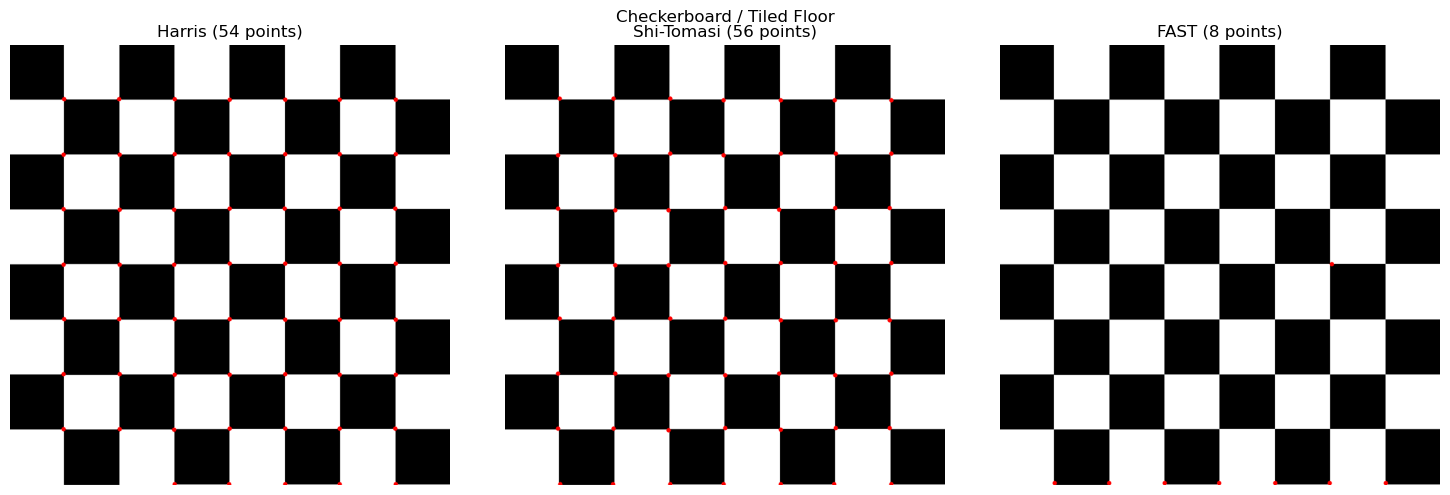

In [107]:
######################################################
# DISPLAY RESULTS FOR CHECKERBOARD
#####################################################
display_results(
    checkerboard,
    checkerboard_results,
    "Checkerboard / Tiled Floor"
)

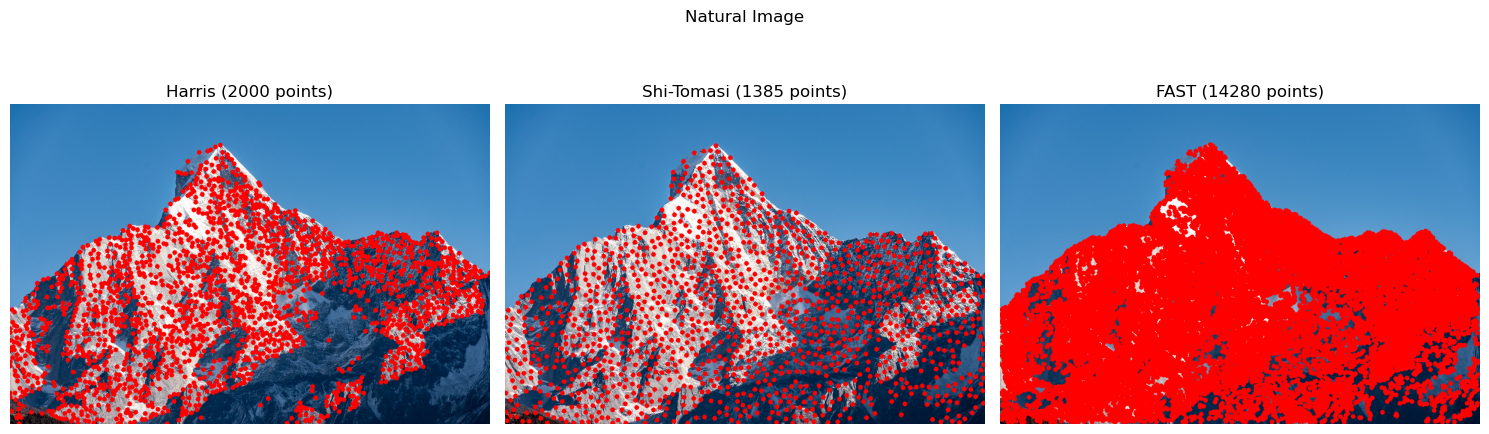

In [108]:
######################################################
# DISPLAY RESULTS FOR NATUREAL
#####################################################
display_results(
    natural,
    natural_results,
    "Natural Image"
)

In [109]:
# Print comparison table
create_results_table(
    checkerboard_results,
    natural_results
)


Image                    Detector       Points    Time (ms)   
--------------------------------------------------------------
Checkerboard             Harris         54        13.23       
Checkerboard             Shi-Tomasi     56        10.83       
Checkerboard             FAST           8         1.73        
Natural Image            Harris         2000      10.00       
Natural Image            Shi-Tomasi     1385      10.09       
Natural Image            FAST           14280     6.97        


#### Paragraph
The three feature detectors were evaluated on a checkerboard image and a natural mountain image. On the checkerboard, Harris and Shi-Tomasi produced very similar results, detecting 54 and 56 points respectively. This is expected because both methods identify locations with strong intensity changes in two directions, particularly at the intersections of the checkerboard squares. FAST detected only 8 points, but was considerably faster, taking 1.73 ms compared with 13.23 ms for Harris and 10.83 ms for Shi-Tomasi.

On the natural mountain image, the detectors produced more varied results. Harris detected 2,000 points, Shi-Tomasi detected 1,385 points, and FAST detected 14,280 points. The larger number of features in the natural image is due to the presence of intensity and texture variations such as mountain edges, and rocky regions. FAST produced by far the largest number of points because it responds to many local intensity patterns, while Harris and Shi-Tomasi are more selective. In terms of speed, FAST was again the fastest at 6.97 ms, followed by Harris at 10.00 ms and Shi-Tomasi at 10.09 ms. Overall, Harris and Shi-Tomasi produced relatively selective and comparable corner detections, whereas FAST provided many more features at a significantly lower computational cost.


## Task 2. Descriptors and an invariance experiment

In [135]:
task_image = cv2.imread(natural_path)

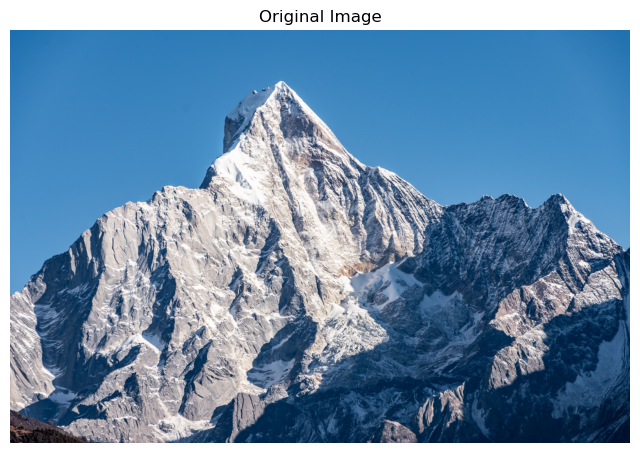

In [136]:
#################################
# DISPLAY THE IMAGE
#################################

def display_image(image, title="Image"):
    plt.figure(figsize=(8, 6))

    if len(image.shape) == 3:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(image, cmap="gray")

    plt.title(title)
    plt.axis("off")
    plt.show()


display_image(task_image, "Original Image")

In [137]:
#################################
# ROTATE THE IMAGE
#################################

def rotate_image(image, angle):
    height, width = image.shape[:2]

    center = (width / 2, height / 2)

    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    rotated = cv2.warpAffine(
        image,
        matrix,
        (width, height)
    )

    return rotated, matrix

In [138]:
#################################
# SCALING THE IMAGE
#################################

def scale_image(image, scale):
    height, width = image.shape[:2]

    new_width = int(width * scale)
    new_height = int(height * scale)

    matrix = np.array([
        [scale, 0, 0],
        [0, scale, 0]
    ], dtype=np.float32)

    scaled = cv2.warpAffine(
        image,
        matrix,
        (new_width, new_height)
    )

    return scaled, matrix

In [139]:
#################################
# DETECT AND DESCRIBE WITH ORB
#################################

def detect_orb(image, n_features=2000):
    orb = cv2.ORB_create(nfeatures=n_features)

    keypoints, descriptors = orb.detectAndCompute(
        image,
        None
    )

    return keypoints, descriptors

In [140]:
#################################
# DETECT AND DESCRIBE WITH SIFT
#################################

def detect_sift(image, n_features=2000):
    sift = cv2.SIFT_create(nfeatures=n_features)

    keypoints, descriptors = sift.detectAndCompute(
        image,
        None
    )

    return keypoints, descriptors

In [141]:
#################################
# MATCH DESCRIPTORS
#################################

def match_descriptors(
    original_descriptors,
    transformed_descriptors,
    detector
):
    if original_descriptors is None or transformed_descriptors is None:
        return []

    if detector == "ORB":
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    elif detector == "SIFT":
        matcher = cv2.BFMatcher(cv2.NORM_L2)
    else:
        raise ValueError("Detector must be 'ORB' or 'SIFT'")

    matches = matcher.knnMatch(
        original_descriptors,
        transformed_descriptors,
        k=2
    )

    good_matches = []

    for pair in matches:
        if len(pair) < 2:
            continue

        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    return good_matches

In [142]:
#######################################
# PREDICT WHERE THE KEYPOINT WILL MOVE
#######################################

def transform_points(points, matrix):
    points = np.asarray(points, dtype=np.float32)

    ones = np.ones(
        (points.shape[0], 1),
        dtype=np.float32
    )

    homogeneous_points = np.hstack([
        points,
        ones
    ])

    transformed = homogeneous_points @ matrix.T

    return transformed

In [143]:
#################################
# CALCULATE REPEATABILITY
#################################

def calculate_repeatability(
    original_keypoints,
    transformed_keypoints,
    matches,
    matrix,
    threshold=3.0
):
    if len(original_keypoints) == 0:
        return 0.0

    # Original keypoint coordinates
    original_points = np.array([
        kp.pt for kp in original_keypoints
    ], dtype=np.float32)

    # Predicted locations after transformation
    predicted_points = transform_points(
        original_points,
        matrix
    )

    correct_matches = 0

    for match in matches:

        original_index = match.queryIdx
        transformed_index = match.trainIdx

        predicted = predicted_points[original_index]

        actual = np.array(
            transformed_keypoints[transformed_index].pt,
            dtype=np.float32
        )

        distance = np.linalg.norm(
            predicted - actual
        )

        if distance <= threshold:
            correct_matches += 1

    repeatability = (
        correct_matches /
        len(original_keypoints)
    ) * 100

    return repeatability

In [144]:
#############################################################
# FUNCTION TO PERFORM WHOLE EXPERIMENT FOR EITHER ORB OR SIFT
#############################################################
def evaluate_detector(
    original_image,
    transformed_image,
    matrix,
    detector_name
):
    # Detect features in original image
    if detector_name == "ORB":
        original_kp, original_desc = detect_orb(
            original_image
        )

        transformed_kp, transformed_desc = detect_orb(
            transformed_image
        )

    elif detector_name == "SIFT":
        original_kp, original_desc = detect_sift(
            original_image
        )

        transformed_kp, transformed_desc = detect_sift(
            transformed_image
        )

    else:
        raise ValueError(
            "Detector must be ORB or SIFT"
        )

    # Match descriptors
    matches = match_descriptors(
        original_desc,
        transformed_desc,
        detector_name
    )

    # Calculate repeatability
    repeatability = calculate_repeatability(
        original_kp,
        transformed_kp,
        matches,
        matrix,
        threshold=3.0
    )

    return {
        "detector": detector_name,
        "original_keypoints": len(original_kp),
        "transformed_keypoints": len(transformed_kp),
        "matches": len(matches),
        "repeatability": repeatability,
        "original_kp": original_kp,
        "transformed_kp": transformed_kp,
        "matches_list": matches
    }

In [145]:
#######################################
# FUNCTION FOR THE COMPLETE EXPERIMENT
#######################################

def run_invariance_experiment(image):
    transformations = {}

    # Original
    transformations["Original"] = (
        image,
        np.array([
            [1, 0, 0],
            [0, 1, 0]
        ], dtype=np.float32)
    )

    # 30 degree rotation
    image_30, M_30 = rotate_image(image, 30)

    transformations["Rotate 30°"] = (
        image_30,
        M_30
    )

    # 90 degree rotation
    image_90, M_90 = rotate_image(image, 90)

    transformations["Rotate 90°"] = (
        image_90,
        M_90
    )

    # 0.5 scale
    image_half, M_half = scale_image(image, 0.5)

    transformations["Scale 0.5×"] = (
        image_half,
        M_half
    )

    results = []

    for detector in ["ORB", "SIFT"]:

        for transform_name, (
            transformed_image,
            matrix
        ) in transformations.items():

            if transform_name == "Original":
                continue

            result = evaluate_detector(
                image,
                transformed_image,
                matrix,
                detector
            )

            results.append({
                "Detector": detector,
                "Transform": transform_name,
                "Original Keypoints":
                    result["original_keypoints"],
                "Transformed Keypoints":
                    result["transformed_keypoints"],
                "Good Matches":
                    result["matches"],
                "Repeatability (%)":
                    round(
                        result["repeatability"],
                        2
                    )
            })

    return pd.DataFrame(results)

In [146]:
#################################
# RESULTS TABLE
#################################

results_df = run_invariance_experiment(task_image)
repeatability_table = results_df[
    ["Detector", "Transform", "Repeatability (%)"]
]

print(repeatability_table.to_string(index=False))


Detector  Transform  Repeatability (%)
     ORB Rotate 30°              61.85
     ORB Rotate 90°              41.05
     ORB Scale 0.5×              27.10
    SIFT Rotate 30°              70.15
    SIFT Rotate 90°              54.85
    SIFT Scale 0.5×              46.40


#### Explanation
For the mountain image, SIFT achieved higher repeatability than ORB for all three transformations. Under a 30° rotation, ORB achieved 61.85% repeatability compared with 70.15% for SIFT. For a 90° rotation, the repeatability decreased to 41.05% for ORB and 54.85% for SIFT. Under 0.5× scaling, ORB achieved 27.10%, whereas SIFT achieved 46.40%.

The higher performance of SIFT is consistent with how the two methods achieve invariance. SIFT is designed to provide strong scale and rotation invariance. It detects features across multiple scales using a scale-space representation and assigns a dominant orientation to each keypoint based on local image gradients. This allows corresponding features to be detected and described even when the image is rotated or resized. ORB also provides rotation invariance by estimating the orientation of FAST keypoints and using an orientation-aware BRIEF descriptor. However, its scale invariance is more limited because it relies on an image pyramid rather than SIFT's scale-space approach. This is particularly evident in the 0.5× experiment, where SIFT outperformed ORB by 19.30 percentage points.
